# HR Workforce Analytics

## Introduction

Employee attrition is an important concern for organisations because losing employees can affect productivity, workforce stability, and recruitment costs.

This project uses the IBM HR Analytics Employee Attrition and Performance dataset to examine employee attrition patterns and identify factors associated with employees leaving the organisation.

The analysis explores attrition across different employee characteristics, including department, gender, marital status, job satisfaction, work-life balance, years at the company, and job role.

The goal is to uncover meaningful insights and provide data-driven recommendations that can help improve employee retention.

# 1. Project Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
hr= pd.read_csv('IBM HR Analytics.csv')

# 2. Data Understanding

In [53]:
hr.shape

(1470, 35)

In [10]:
hr.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')

In [11]:
hr.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [13]:
hr.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [14]:
hr.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [15]:
hr.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


# 3. Data Cleaning

In [16]:
#to check for duplicated info
hr.duplicated().sum()

np.int64(0)

In [17]:
#to check for duplicated employee number
hr['EmployeeNumber'].duplicated().sum()

np.int64(0)

# 4. Exploratory Data Analysis (EDA)

In [18]:
# Check the distribution of employees who left and stayed
hr['Attrition'].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [19]:
# Calculate the percentage of employees who left and stayed
hr['Attrition'].value_counts(normalize=True) * 100

Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64

The analysis shows that 237 employees (16.12%) left the organisation, while 1,233 employees (83.88%) remained. This indicates that employee attrition accounts for a relatively small proportion of the workforce.

In [20]:
# Compare employee attrition across departments
hr.groupby(['Department', 'Attrition']).size().unstack()

Attrition,No,Yes
Department,,
Human Resources,51,12
Research & Development,828,133
Sales,354,92


Research & Development recorded the highest number of employee exits (133), followed by Sales (92) and Human Resources (12).
However, these are raw counts. Since the departments have different workforce sizes, we should compare their attrition percentages before concluding which department has the highest attrition rate.

In [21]:
# Calculate employee attrition percentages within each department
hr.groupby('Department')['Attrition'].value_counts(normalize=True).unstack() * 100

Attrition,No,Yes
Department,,
Human Resources,80.952381,19.047619
Research & Development,86.160250,13.839750
Sales,79.372197,20.627803


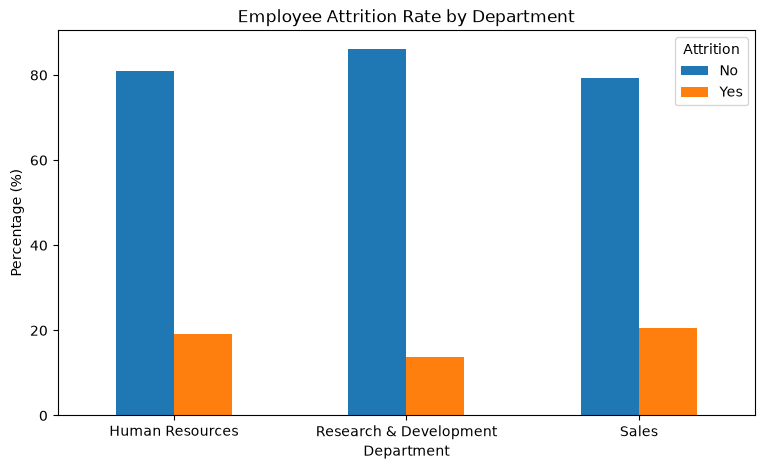

In [22]:
# Visualize employee attrition percentages across departments
attrition_dept = hr.groupby('Department')['Attrition'].value_counts(normalize=True).unstack() * 100

attrition_dept.plot(kind='bar', figsize=(9,5))
plt.title('Employee Attrition Rate by Department')
plt.xlabel('Department')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Attrition')
plt.show()

Sales recorded the highest employee attrition rate (20.63%), followed by Human Resources (19.05%), while Research & Development had the lowest rate (13.84%).

In [23]:
# Compare employee attrition across genders
hr.groupby('Gender')['Attrition'].value_counts(normalize=True).unstack() * 100

Attrition,No,Yes
Gender,,
Female,85.204082,14.795918
Male,82.993197,17.006803


Male employees recorded a slightly higher attrition rate (17.01%) than female employees (14.80%), indicating a small difference in employee exits across genders. Lets investigate gender-based attrition across departments

In [24]:
# Compare employee attrition across gender within each department
hr.groupby(['Department', 'Gender'])['Attrition'].value_counts(normalize=True).unstack() * 100

Attrition                             No        Yes
Department             Gender                      
Human Resources        Female  70.000000  30.000000
                       Male    86.046512  13.953488
Research & Development Female  88.654354  11.345646
                       Male    84.536082  15.463918
Sales                  Female  79.894180  20.105820
                       Male    78.988327  21.011673

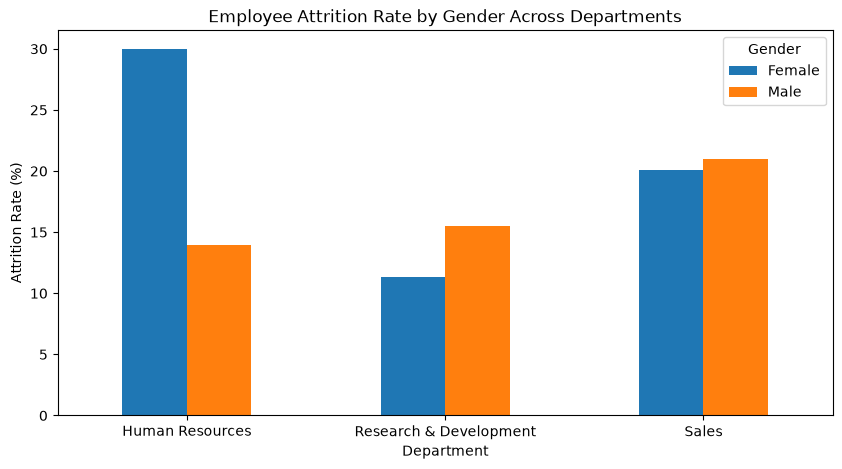

In [25]:
# Visualize attrition rates by gender across departments
gender_dept = hr.groupby(['Department', 'Gender'])['Attrition'].value_counts(normalize=True).unstack() * 100

gender_dept['Yes'].unstack().plot(kind='bar', figsize=(10,5))
plt.title('Employee Attrition Rate by Gender Across Departments')
plt.xlabel('Department')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.legend(title='Gender')
plt.show()

Female employees in Human Resources recorded a higher attrition rate (30%) than males (13.95%). In Research & Development and Sales, male employees recorded slightly higher attrition rates than females. The largest gender difference was observed in Human Resources. Let's see whether marital status is a determining factor for attrition.

In [26]:
# Compare employee attrition rates across marital status groups
hr.groupby('MaritalStatus')['Attrition'].value_counts(normalize=True).unstack() * 100

Attrition,No,Yes
MaritalStatus,,
Divorced,89.908257,10.091743
Married,87.518574,12.481426
Single,74.468085,25.531915


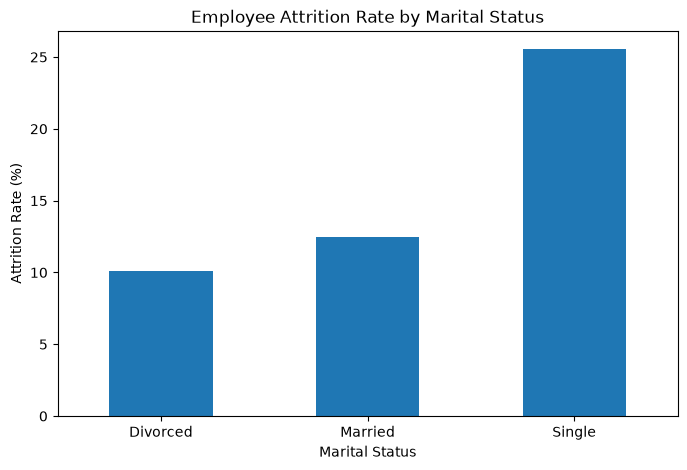

In [27]:
# Visualize employee attrition rates by marital status
marital_attrition = hr.groupby('MaritalStatus')['Attrition'].value_counts(normalize=True).unstack() * 100

marital_attrition['Yes'].plot(kind='bar', figsize=(8,5))
plt.title('Employee Attrition Rate by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.show()

The analysis shows that single employees recorded the highest attrition rate at 25.53%, compared to married employees at 12.48% and divorced employees at 10.09%. This suggests that single employees are more likely to leave the organisation than employees in the other marital status groups. let's investigate how many employees left in each department, broken down by marital status.

In [29]:
# Count employees who left in each department by marital status
hr[hr['Attrition'] == 'Yes'].groupby(['Department', 'MaritalStatus']).size().unstack(fill_value=0)

MaritalStatus,Divorced,Married,Single
Department,,,
Human Resources,5,6,1
Research & Development,18,49,66
Sales,10,29,53


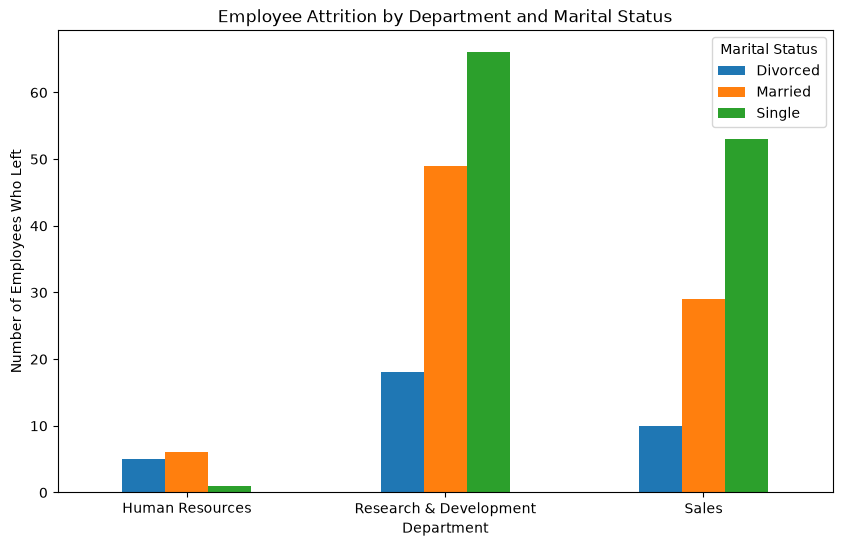

In [30]:
# Visualize employee exits by department and marital status
exit_marital_dept = hr[hr['Attrition'] == 'Yes'].groupby(
    ['Department', 'MaritalStatus']
).size().unstack(fill_value=0)

exit_marital_dept.plot(kind='bar', figsize=(10,6))

plt.title('Employee Attrition by Department and Marital Status')
plt.xlabel('Department')
plt.ylabel('Number of Employees Who Left')
plt.xticks(rotation=0)
plt.legend(title='Marital Status')
plt.show()

The analysis shows that single employees recorded the highest number of exits in both Research & Development (66) and Sales (53). In Human Resources, married employees had the highest number of exits (6), closely followed by divorced employees (5). Overall, Research & Development recorded the highest number of employee exits across the marital status groups.
Key insight: Single employees account for the largest number of exits in Research & Development and Sales.

In [31]:
#First, let's find out whether single employees work overtime more frequently than married or divorced employees.

# Compare overtime participation across marital status groups
hr.groupby('MaritalStatus')['OverTime'].value_counts(normalize=True).unstack() * 100

OverTime,No,Yes
MaritalStatus,,
Divorced,69.724771,30.275229
Married,72.362556,27.637444
Single,72.127660,27.872340


The analysis shows that divorced employees recorded the highest overtime participation rate at 30.28%, followed by single employees at 27.87% and married employees at 27.64%. The differences are relatively small, suggesting that overtime participation is fairly similar across the three marital status groups.

In [33]:
# Compare employee attrition rates by marital status and overtime
hr.groupby(['MaritalStatus', 'OverTime'])['Attrition'].value_counts(normalize=True).unstack() * 100

Attrition                      No        Yes
MaritalStatus OverTime                      
Divorced      No        93.859649   6.140351
              Yes       80.808081  19.191919
Married       No        91.581109   8.418891
              Yes       76.881720  23.118280
Single        No        83.775811  16.224189
              Yes       50.381679  49.618321

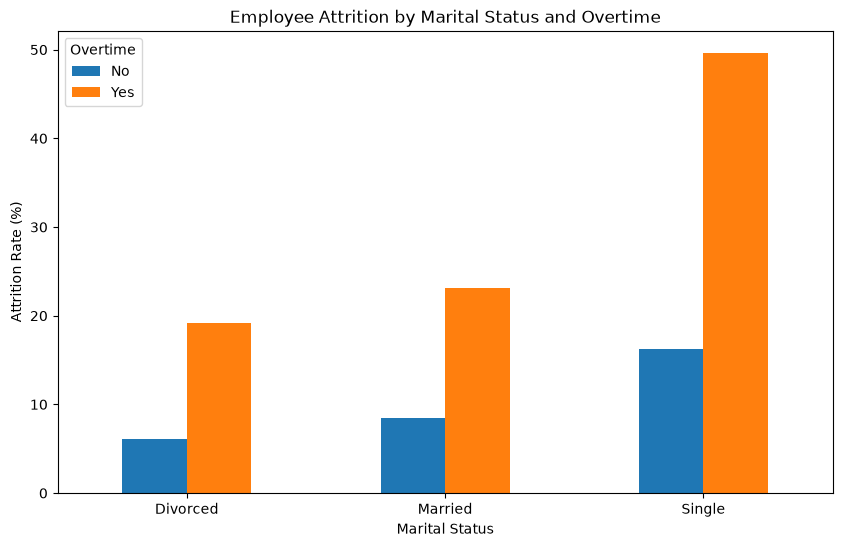

In [34]:
# Visualize attrition rates by marital status and overtime
overtime_attrition = hr.groupby(
    ['MaritalStatus', 'OverTime']
)['Attrition'].value_counts(normalize=True).unstack() * 100

overtime_attrition['Yes'].unstack().plot(
    kind='bar', figsize=(10,6)
)

plt.title('Employee Attrition by Marital Status and Overtime')
plt.xlabel('Marital Status')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.legend(title='Overtime')
plt.show()

The analysis reveals a strong relationship between overtime participation and employee attrition across all marital status groups. Single employees who work overtime recorded the highest attrition rate at 49.62%, compared to 16.22% among those who do not work overtime. Similarly, attrition increased from 8.42% to 23.12% among married employees and from 6.14% to 19.19% among divorced employees. This suggests that overtime participation is associated with higher employee attrition, particularly among single employees.

In [35]:
#Let's investigate whether employees with lower job satisfaction have higher attrition rates.

# Calculate employee attrition rates across job satisfaction levels
hr.groupby('JobSatisfaction')['Attrition'].value_counts(normalize=True).unstack() * 100

Attrition,No,Yes
JobSatisfaction,,
1,77.162630,22.837370
2,83.571429,16.428571
3,83.484163,16.515837
4,88.671024,11.328976


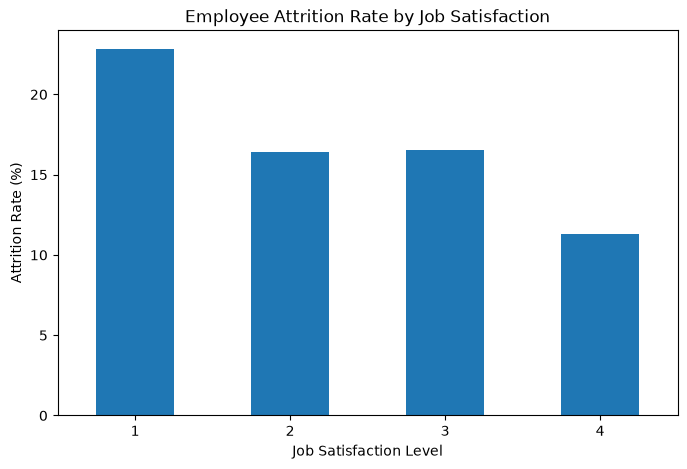

In [36]:
# Visualize employee attrition rates across job satisfaction levels
job_sat = hr.groupby('JobSatisfaction')['Attrition'].value_counts(normalize=True).unstack() * 100

job_sat['Yes'].plot(kind='bar', figsize=(8,5))

plt.title('Employee Attrition Rate by Job Satisfaction')
plt.xlabel('Job Satisfaction Level')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.show()

The analysis shows that employees with low job satisfaction recorded the highest attrition rate at 22.84%, while those with very high satisfaction had the lowest rate at 11.33%. Overall, attrition generally decreases as job satisfaction increases, suggesting a relationship between employee satisfaction and retention.

In [37]:
# Check the job satisfaction levels of employees who left the organisation
hr[hr['Attrition'] == 'Yes']['JobSatisfaction'].value_counts().sort_index()

JobSatisfaction
1    66
2    46
3    73
4    52
Name: count, dtype: int64

Among the 237 employees who left the organisation, 66 had low job satisfaction, 46 had medium satisfaction, 73 had high satisfaction, and 52 had very high satisfaction. Interestingly, employees with high job satisfaction recorded the highest number of exits, indicating that employee departures were not limited to those who were dissatisfied.

In [38]:
#We want to find out whether employees with poorer work-life balance have higher attrition rates

# Calculate employee attrition rates across work-life balance levels
hr.groupby('WorkLifeBalance')['Attrition'].value_counts(normalize=True).unstack() * 100

Attrition,No,Yes
WorkLifeBalance,,
1,68.750000,31.250000
2,83.139535,16.860465
3,85.778275,14.221725
4,82.352941,17.647059


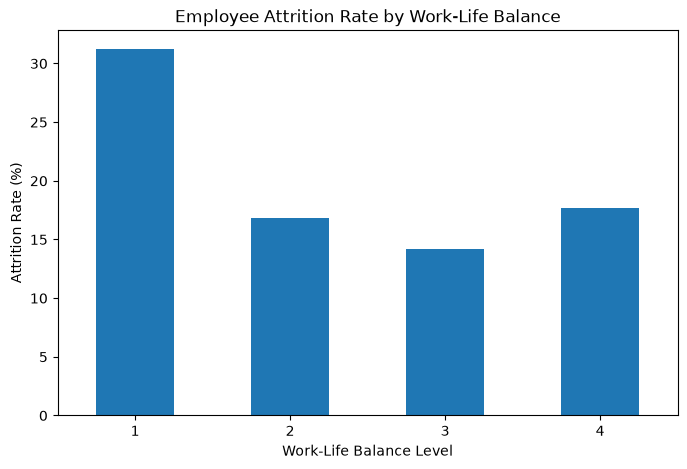

In [39]:
# Visualize employee attrition rates across work-life balance levels
worklife_attrition = hr.groupby('WorkLifeBalance')['Attrition'].value_counts(normalize=True).unstack() * 100

worklife_attrition['Yes'].plot(kind='bar', figsize=(8,5))

plt.title('Employee Attrition Rate by Work-Life Balance')
plt.xlabel('Work-Life Balance Level')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.show()

The analysis shows that employees with poor work-life balance recorded the highest attrition rate at 31.25%, compared to 16.86% for employees with good balance, 14.22% for those with better balance, and 17.65% for those with the best balance. This suggests an association between poor work-life balance and higher employee attrition.

In [40]:
#We want to find out whether employees who have spent fewer years at the organisation are more likely to leave.
# Calculate employee attrition rates across years spent at the company
hr.groupby('YearsAtCompany')['Attrition'].value_counts(normalize=True).unstack() * 100

Attrition,No,Yes
YearsAtCompany,,
0,63.636364,36.363636
1,65.497076,34.502924
2,78.740157,21.259843
3,84.375000,15.625000
4,82.727273,17.272727
5,89.285714,10.714286
6,88.157895,11.842105
7,87.777778,12.222222
8,88.750000,11.250000


In [41]:
# Group employees into tenure categories
hr['TenureGroup'] = pd.cut(
    hr['YearsAtCompany'],
    bins=[-1, 1, 4, 9, 19, 100],
    labels=['0-1 years', '2-4 years', '5-9 years', '10-19 years', '20+ years']
)

# Calculate attrition rates across tenure groups
hr.groupby('TenureGroup', observed=True)['Attrition'].value_counts(normalize=True).unstack() * 100

Attrition,No,Yes
TenureGroup,,
0-1 years,65.116279,34.883721
2-4 years,81.917808,18.082192
5-9 years,88.931298,11.068702
10-19 years,89.377289,10.622711
20+ years,90.322581,9.677419


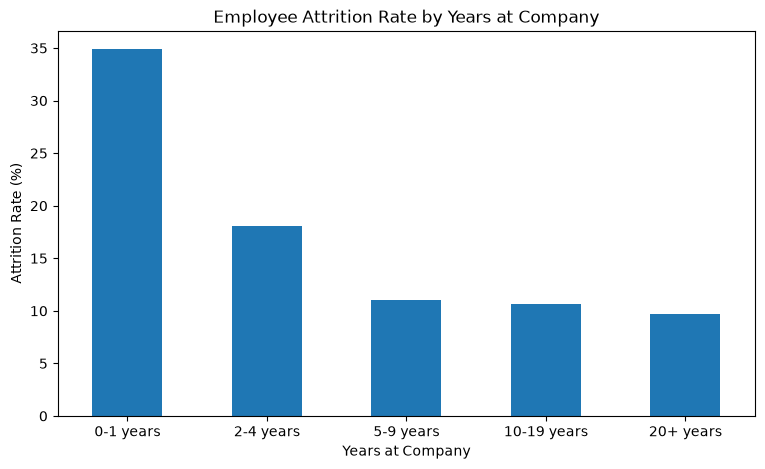

In [42]:
# Visualize employee attrition rates across tenure groups
tenure_attrition = hr.groupby('TenureGroup', observed=True)['Attrition'].value_counts(normalize=True).unstack() * 100

tenure_attrition['Yes'].plot(kind='bar', figsize=(9,5))

plt.title('Employee Attrition Rate by Years at Company')
plt.xlabel('Years at Company')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.show()

The analysis reveals that employees with 0–1 years of service recorded the highest attrition rate at 34.88%. This decreased to 18.08% among employees with 2–4 years of service and continued to decline across longer tenure groups. Employees with 20 or more years of service recorded the lowest attrition rate at 9.68%. This suggests that newer employees are more likely to leave the organisation than longer-serving employees. The organisation may need to pay more attention to employee onboarding, early engagement and retention.

## 4.1 Further Investigation: Sales Representatives

In [43]:
#Lets identify which job roles have the highest proportion of employees leaving the organisation.

# Calculate employee attrition rates across different job roles
hr.groupby('JobRole')['Attrition'].value_counts(normalize=True).unstack() * 100

Attrition,No,Yes
JobRole,,
Healthcare Representative,93.129771,6.870229
Human Resources,76.923077,23.076923
Laboratory Technician,76.061776,23.938224
Manager,95.098039,4.901961
Manufacturing Director,93.103448,6.896552
Research Director,97.500000,2.500000
Research Scientist,83.904110,16.095890
Sales Executive,82.515337,17.484663
Sales Representative,60.240964,39.759036


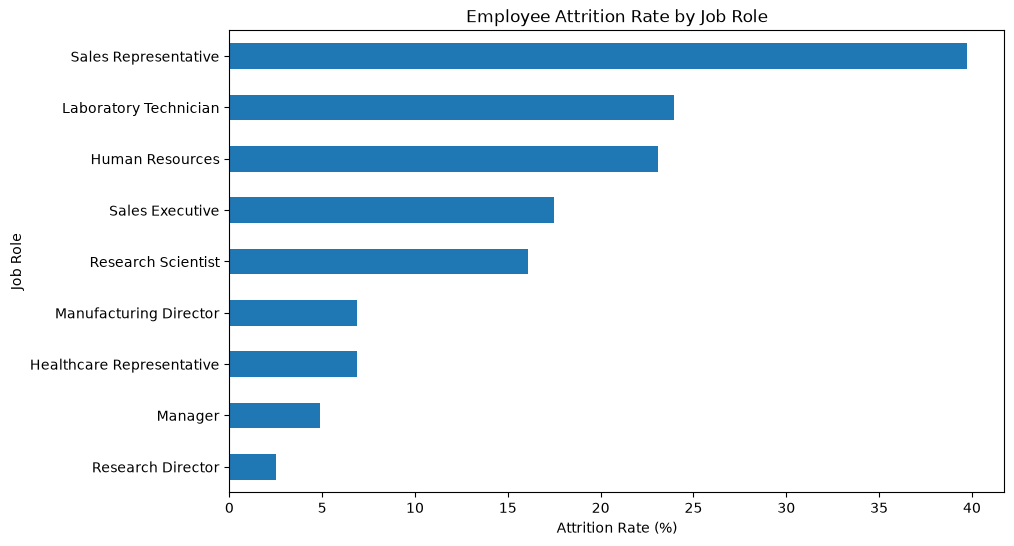

In [44]:
# Visualize employee attrition rates across job roles
jobrole_attrition = hr.groupby('JobRole')['Attrition'].value_counts(normalize=True).unstack() * 100

jobrole_attrition['Yes'].sort_values().plot(
    kind='barh', figsize=(10,6)
)

plt.title('Employee Attrition Rate by Job Role')
plt.xlabel('Attrition Rate (%)')
plt.ylabel('Job Role')
plt.show()

The analysis reveals significant differences in attrition rates across job roles. Sales Representatives recorded the highest attrition rate at 39.76%, followed by Laboratory Technicians at 23.94% and Human Resources employees at 23.08%. Research Directors recorded the lowest attrition rate at 2.50%. This highlights Sales Representatives as a key employee group requiring further attention in the organisation's retention efforts.

In [45]:
#We already know that Sales Representatives have the highest attrition rate (39.76%). 
#Now, let's see whether job satisfaction is associated with their decision to leave.

# Filter Sales Representatives and calculate attrition rates across job satisfaction levels
sales_rep = hr[hr['JobRole'] == 'Sales Representative']

sales_rep.groupby('JobSatisfaction')['Attrition'].value_counts(normalize=True).unstack() * 100

Attrition,No,Yes
JobSatisfaction,,
1,41.666667,58.333333
2,52.380952,47.619048
3,66.666667,33.333333
4,69.565217,30.434783


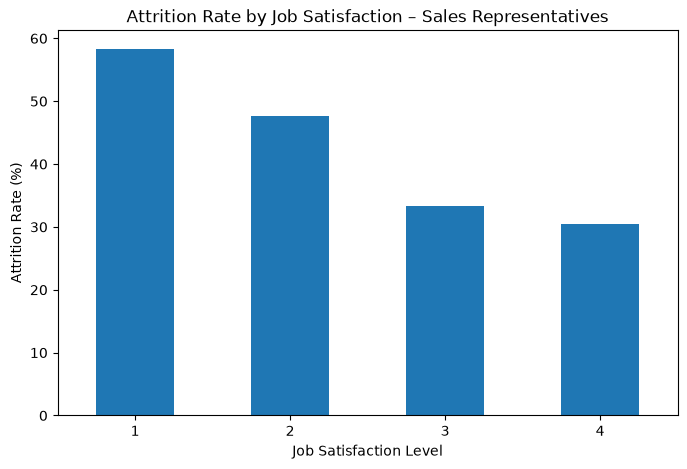

In [46]:
# Visualize attrition rates by job satisfaction among Sales Representatives
sales_sat = sales_rep.groupby('JobSatisfaction')['Attrition'].value_counts(normalize=True).unstack() * 100

sales_sat['Yes'].plot(kind='bar', figsize=(8,5))

plt.title('Attrition Rate by Job Satisfaction – Sales Representatives')
plt.xlabel('Job Satisfaction Level')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.show()

The analysis reveals that Sales Representatives with low job satisfaction recorded the highest attrition rate at 58.33%, compared to 47.62% among those with medium satisfaction, 33.33% among those with high satisfaction, and 30.43% among those with very high satisfaction. This suggests an association between lower job satisfaction and higher employee attrition within this job role.
In other words, Sales Representatives with lower job satisfaction were more likely to leave than those with higher satisfaction.

In [47]:
#Overtime and Attrition among Sales Representatives.
# Calculate attrition rates among Sales Representatives based on overtime participation
sales_rep.groupby('OverTime')['Attrition'].value_counts(normalize=True).unstack() * 100

Attrition,No,Yes
OverTime,,
No,71.186441,28.813559
Yes,33.333333,66.666667


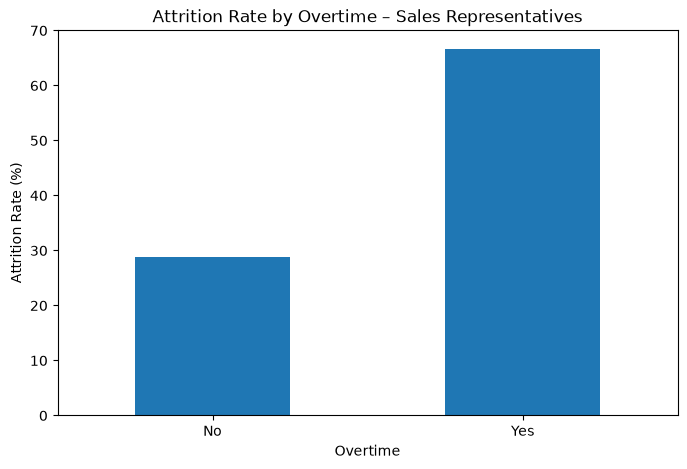

In [48]:
# Visualize attrition rates by overtime participation among Sales Representatives
sales_overtime = sales_rep.groupby('OverTime')['Attrition'].value_counts(normalize=True).unstack() * 100

sales_overtime['Yes'].plot(kind='bar', figsize=(8,5))

plt.title('Attrition Rate by Overtime – Sales Representatives')
plt.xlabel('Overtime')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.show()

The analysis reveals that Sales Representatives who work overtime recorded a significantly higher attrition rate of 66.67%, compared to 28.81% among those who do not work overtime. This suggests a strong association between overtime participation and employee attrition within this job role.

In [49]:
#Monthly Income and Attrition among Sales Representatives.
# Compare average monthly income of Sales Representatives by attrition status
sales_rep.groupby('Attrition')['MonthlyIncome'].mean()

Attrition
No     2798.440000
Yes    2364.727273
Name: MonthlyIncome, dtype: float64

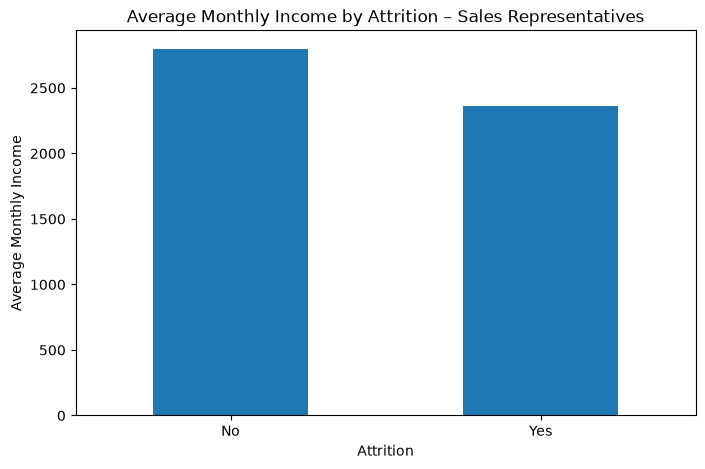

In [50]:
# Visualize average monthly income by attrition status among Sales Representatives
sales_rep.groupby('Attrition')['MonthlyIncome'].mean().plot(
    kind='bar', figsize=(8,5)
)

plt.title('Average Monthly Income by Attrition – Sales Representatives')
plt.xlabel('Attrition')
plt.ylabel('Average Monthly Income')
plt.xticks(rotation=0)
plt.show()

The analysis shows that Sales Representatives who left the organisation earned an average monthly income of 2,364.73, compared to 2,798.44 among those who stayed. This indicates that employees who left generally earned less than those who remained, suggesting a possible association between lower monthly income and employee attrition.

# 5. Key Findings

#Report summary

Further investigation into Sales Representatives revealed several factors associated with employee attrition. Employees with low job satisfaction recorded the highest attrition rate (58.33%), while those who worked overtime recorded an attrition rate of 66.67%. Additionally, employees who left earned a lower average monthly income (2,364.73) than those who stayed (2,798.44). These findings highlight Sales Representatives as an important group for further investigation and targeted employee retention efforts.

The analysis revealed several important patterns associated with employee attrition:

| Area Analysed | Key Finding |
|---|---|
| Overall Attrition | 16.12% of employees left the organisation. |
| Department | Sales recorded the highest attrition rate at 20.63%. |
| Gender | Male employees had a slightly higher attrition rate (17.01%) than female employees (14.80%). |
| Marital Status | Single employees recorded the highest attrition rate at 25.53%. |
| Overtime | Employees who worked overtime had higher attrition rates across all marital status groups. |
| Job Satisfaction | Employees with low job satisfaction recorded a higher attrition rate (22.84%) than those with very high satisfaction (11.33%). |
| Work-Life Balance | Employees with poor work-life balance recorded the highest attrition rate at 31.25%. |
| Employee Tenure | Employees with 0–1 years of service recorded the highest attrition rate at 34.88%. |
| Job Role | Sales Representatives recorded the highest attrition rate at 39.76%. |

### Further Investigation: Sales Representatives

Further analysis revealed that:
- Employees with low job satisfaction had an attrition rate of 58.33%.
- Employees who worked overtime had an attrition rate of 66.67%.
- Employees who left earned a lower average monthly income (2,364.73) than those who stayed (2,798.44).

These findings highlight employee tenure, job satisfaction, work-life balance, overtime participation and specific job roles as important areas for further investigation.

# 6. Business Recommendations


Based on the findings from the HR Workforce Analytics, the following recommendations are proposed:

1. **Improve Employee Onboarding:** The organisation should strengthen its onboarding and mentorship programmes to support new employees and improve early employee retention, particularly during their first year.

2. **Promote Work-Life Balance:** Management should review workload distribution and overtime practices to reduce excessive work demands.

3. **Improve Employee Satisfaction:** Regular employee satisfaction surveys should be conducted to identify workplace concerns and improve employee engagement.

4. **Review Sales Representative Retention:** Since Sales Representatives recorded the highest attrition rate, the organisation should investigate the specific challenges affecting this group and develop targeted retention strategies.

5. **Review Compensation Practices:** The organisation should examine compensation differences among employees, particularly within high-attrition job roles, to identify possible pay-related concerns.

# 7. Conclusion

The HR Workforce Analytics project examined employee attrition patterns and identified several factors associated with employees leaving the organisation. The analysis revealed higher attrition rates among employees with shorter tenure, poor work-life balance, and low job satisfaction. Sales Representatives recorded the highest attrition rate among the job roles examined. Further investigation also revealed that overtime participation and lower average monthly income were associated with higher attrition within this group.

These findings highlight the importance of improving employee onboarding, promoting work-life balance, reviewing overtime practices, and strengthening retention strategies, particularly for job roles with higher attrition rates.

# 8. Machine Learning – Employee Attrition Prediction

In [3]:
## 8.1 Feature Preparation

# Check the number of unique values in each column
hr.nunique().sort_values()

EmployeeCount                  1
Over18                         1
StandardHours                  1
Attrition                      2
OverTime                       2
PerformanceRating              2
Gender                         2
BusinessTravel                 3
Department                     3
MaritalStatus                  3
RelationshipSatisfaction       4
StockOptionLevel               4
JobSatisfaction                4
EnvironmentSatisfaction        4
JobInvolvement                 4
WorkLifeBalance                4
Education                      5
JobLevel                       5
EducationField                 6
TrainingTimesLastYear          7
JobRole                        9
NumCompaniesWorked            10
PercentSalaryHike             15
YearsSinceLastPromotion       16
YearsWithCurrManager          18
YearsInCurrentRole            19
DistanceFromHome              29
YearsAtCompany                37
TotalWorkingYears             40
Age                           43
HourlyRate

In [4]:
## 8.2 Correlation Analysis
# Examine correlations between numerical features to identify highly correlated variables and reduce redundancy.

# Calculate correlations between numerical columns
correlation_matrix = hr.corr(numeric_only=True)

# Display the correlation matrix
correlation_matrix

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
Age,1.000000,0.010661,-0.001686,0.208034,NaN,-0.010145,0.010146,0.024287,0.029820,0.509604,...,0.053535,NaN,0.037510,0.680381,-0.019621,-0.021490,0.311309,0.212901,0.216513,0.202089
DailyRate,0.010661,1.000000,-0.004985,-0.016806,NaN,-0.050990,0.018355,0.023381,0.046135,0.002966,...,0.007846,NaN,0.042143,0.014515,0.002453,-0.037848,-0.034055,0.009932,-0.033229,-0.026363
DistanceFromHome,-0.001686,-0.004985,1.000000,0.021042,NaN,0.032916,-0.016075,0.031131,0.008783,0.005303,...,0.006557,NaN,0.044872,0.004628,-0.036942,-0.026556,0.009508,0.018845,0.010029,0.014406
Education,0.208034,-0.016806,0.021042,1.000000,NaN,0.042070,-0.027128,0.016775,0.042438,0.101589,...,-0.009118,NaN,0.018422,0.148280,-0.025100,0.009819,0.069114,0.060236,0.054254,0.069065
EmployeeCount,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeNumber,-0.010145,-0.050990,0.032916,0.042070,NaN,1.000000,0.017621,0.035179,-0.006888,-0.018519,...,-0.069861,NaN,0.062227,-0.014365,0.023603,0.010309,-0.011240,-0.008416,-0.009019,-0.009197
EnvironmentSatisfaction,0.010146,0.018355,-0.016075,-0.027128,NaN,0.017621,1.000000,-0.049857,-0.008278,0.001212,...,0.007665,NaN,0.003432,-0.002693,-0.019359,0.027627,0.001458,0.018007,0.016194,-0.004999
HourlyRate,0.024287,0.023381,0.031131,0.016775,NaN,0.035179,-0.049857,1.000000,0.042861,-0.027853,...,0.001330,NaN,0.050263,-0.002334,-0.008548,-0.004607,-0.019582,-0.024106,-0.026716,-0.020123
JobInvolvement,0.029820,0.046135,0.008783,0.042438,NaN,-0.006888,-0.008278,0.042861,1.000000,-0.012630,...,0.034297,NaN,0.021523,-0.005533,-0.015338,-0.014617,-0.021355,0.008717,-0.024184,0.025976
JobLevel,0.509604,0.002966,0.005303,0.101589,NaN,-0.018519,0.001212,-0.027853,-0.012630,1.000000,...,0.021642,NaN,0.013984,0.782208,-0.018191,0.037818,0.534739,0.389447,0.353885,0.375281


In [5]:
# Remove unnecessary and highly correlated columns
# EmployeeCount, Over18 and StandardHours were removed because they contain constant values.
# EmployeeNumber was removed because it is only an employee identifier.
# JobLevel was removed because it is highly correlated with MonthlyIncome (0.95).
hr.drop(columns=[
    'EmployeeCount',
    'Over18',
    'StandardHours',
    'EmployeeNumber',
    'JobLevel'
], inplace=True)

In [6]:
# Check the updated dataset dimensions
hr.shape

(1470, 30)

## 8.2 Separating Features and Target Variable

In [8]:
# Separate the independent variables (features) from the dependent variable (target)
X = hr.drop(columns=['Attrition'])
y = hr['Attrition']

In [12]:
X.shape

(1470, 29)

In [13]:
y.shape

(1470,)

## 8.3 Splitting the Dataset into Training and Testing Sets

The dataset was split into 80% training data and 20% testing data. The training data will be used to train the model, while the testing data will be used to evaluate its performance on unseen data.

In [70]:
from sklearn.model_selection import train_test_split  # Import the function for splitting data into training and testing sets
from sklearn.preprocessing import OneHotEncoder  # Import OneHotEncoder for converting categorical variables into numerical values
from scipy.sparse import hstack  # Import hstack to combine numerical and encoded categorical features
from sklearn.preprocessing import StandardScaler  # Import StandardScaler for scaling numerical features
from sklearn.linear_model import LogisticRegression  # Import Logistic Regression for employee attrition prediction
from sklearn.metrics import accuracy_score  # Import accuracy_score to measure the model's prediction accuracy
from sklearn.metrics import confusion_matrix  # Import confusion_matrix to evaluate the model's predictions
from sklearn.metrics import classification_report # Import classification_report to evaluate precision, recall and F1-score
from sklearn.ensemble import RandomForestClassifier  # Import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score  # Import the evaluation metrics

In [20]:
# Split the dataset into 80% training data and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [21]:
# Check the dimensions of the training and testing sets
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1176, 29), (294, 29), (1176,), (294,))

## 8.4 Encoding Categorical Variables

In [22]:
# Identify categorical and numerical columns in the training dataset
categorical_cols = X_train.select_dtypes(include=['object']).columns
numerical_cols = X_train.select_dtypes(exclude=['object']).columns

print("Categorical columns:", list(categorical_cols))
print("Numerical columns:", list(numerical_cols))

Categorical columns: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
Numerical columns: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


C:\Users\HP\AppData\Local\Temp\ipykernel_3892\1364319376.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include=['object']).columns


In [23]:
# Initialize the encoder to handle categorical variables
encoder = OneHotEncoder(handle_unknown='ignore')

In [24]:
# Learn the categories from the training data and transform the categorical columns
X_train_encoded = encoder.fit_transform(X_train[categorical_cols])

# Apply the same encoding to the testing data
X_test_encoded = encoder.transform(X_test[categorical_cols])

In [26]:
# Combine numerical and encoded categorical features
X_train_final = hstack([X_train[numerical_cols].values, X_train_encoded])
X_test_final = hstack([X_test[numerical_cols].values, X_test_encoded])

In [27]:
# Check the dimensions of the final training and testing datasets
X_train_final.shape, X_test_final.shape

((1176, 50), (294, 50))

## 8.5 Encoding the Target Variable 'Attrition'

In [31]:
# Convert the target variable from text labels to numerical values
y_train = y_train.map({'Yes': 1, 'No': 0})
y_test = y_test.map({'Yes': 1, 'No': 0})

In [32]:
# Check the distribution of the encoded target variable
y_train.value_counts()

Attrition
0    986
1    190
Name: count, dtype: int64

## 8.6 Scaling Numerical Features
we need to scale the numerical features because they have different ranges. For example, Age and MonthlyIncome have very different values.
We'll use StandardScaler.  This transforms numerical values so that:
- The mean (average) becomes approximately 0.
- The standard deviation becomes approximately 1.
Also, Logistic Regression benefits from features being on comparable scales.

In [37]:
# Initialize the scaler
scaler = StandardScaler()

# Fit the scaler on training data and transform it
X_train_num_scaled = scaler.fit_transform(X_train[numerical_cols])

# Apply the same scaling to the testing data
X_test_num_scaled = scaler.transform(X_test[numerical_cols])

## 8.7 Combining Numerical and Categorical Features

In [38]:
# Combine scaled numerical features and encoded categorical features
X_train_final = hstack([X_train_num_scaled, X_train_encoded])
X_test_final = hstack([X_test_num_scaled, X_test_encoded])

In [39]:
# Check the shape of the final training and testing datasets
X_train_final.shape, X_test_final.shape

((1176, 50), (294, 50))

## 8.8 Building the Logistic Regression Model

In [41]:
# Initialize the Logistic Regression model

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

## 8.9 Training/Building the Logistic Regression Model

In [43]:
# Train the Logistic Regression model using the training data
Lm= logistic_model.fit(X_train_final, y_train)

## 8.10 Making Predictions with the Trained Model

In [44]:
# Use the trained model to predict employee attrition on the test data
y_pred = Lm.predict(X_test_final)

## 8.11 Evaluating the Model's Performance

In [47]:
# Calculate the accuracy of the model
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy: {:.2%}".format(accuracy))

Model Accuracy: 77.21%


## 8.12 Confusion Matrix
We'll use a confusion matrix to examine:
- Employees who stayed and were correctly predicted.
- Employees who left and were correctly predicted.
- Incorrect predictions.

In [49]:
# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[196  51]
 [ 16  31]]


## 8.13 Classification Report

In [51]:
# Generate the classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.79      0.85       247
           1       0.38      0.66      0.48        47

    accuracy                           0.77       294
   macro avg       0.65      0.73      0.67       294
weighted avg       0.84      0.77      0.79       294



## 8.14 ROC-AUC Score

In [52]:
# Import roc_auc_score to evaluate the model's ability to distinguish between classes
from sklearn.metrics import roc_auc_score

In [53]:
# Calculate the ROC-AUC score using predicted probabilities
y_prob = Lm.predict_proba(X_test_final)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score: {:.2f}".format(roc_auc))

ROC-AUC Score: 0.81


## 8.15 Building the Random Forest Classifier Model
#Random Forest is introduced to compare its performance with Logistic Regression and capture more complex relationships in the data.

In [55]:
# Initialize the Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)

## 8.16 Training the Random Forest Model

In [57]:
# Train the Random Forest model using the training data
Rf= rf_model.fit(X_train_final, y_train)

## 8.17 Making Predictions with the Random Forest Model 

In [58]:
# Use the trained Random Forest model to predict employee attrition
y_pred_rf = Rf.predict(X_test_final)

## 8.18 Evaluating the Random Forest Model

In [59]:
# Calculate the accuracy of the Random Forest model
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy: {:.2%}".format(accuracy_rf))

Random Forest Accuracy: 85.37%


## 8.19 Confusion Matrix – Random Forest

In [60]:
# Generate the Random Forest confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

[[232  15]
 [ 28  19]]


## 8.20 Classification Report – Random Forest

In [61]:
# Generate the classification report for the Random Forest model
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.89      0.94      0.92       247
           1       0.56      0.40      0.47        47

    accuracy                           0.85       294
   macro avg       0.73      0.67      0.69       294
weighted avg       0.84      0.85      0.84       294



## 8.21 ROC-AUC Score – Random Forest

In [62]:
# Calculate the probability of employees leaving
y_prob_rf = Rf.predict_proba(X_test_final)[:, 1]

# Calculate the ROC-AUC score
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest ROC-AUC: {:.2f}".format(roc_auc_rf))

Random Forest ROC-AUC: 0.77


## 8.22 Model Performance Comparison

The two machine learning models produced different results. Random Forest achieved a higher accuracy of 85.37%, while Logistic Regression achieved 77.21%.

However, Logistic Regression performed better in identifying employees who actually left the organisation, with a recall of 66% compared to Random Forest's 40%.

Since the main objective of this project is to identify employees at risk of leaving, Logistic Regression is selected as the preferred model for further improvement.

## 8.23 Improving Logistic Regression – Threshold Adjustment

In [63]:
# View the predicted probabilities for the first 10 employees
y_prob[:10]

array([0.28802466, 0.02314173, 0.40412867, 0.035573  , 0.68966368,
       0.60033425, 0.07448299, 0.11720659, 0.02774984, 0.21955265])

In [65]:
# Adjust the prediction threshold from 0.5 to 0.4
y_pred_04 = (y_prob >= 0.4).astype(int)

In [66]:
# Generate the confusion matrix using the adjusted threshold
cm_04 = confusion_matrix(y_test, y_pred_04)

print(cm_04)

[[178  69]
 [ 10  37]]


## Classification Report at 0.4

In [68]:
# Generate the classification report using the adjusted threshold
print(classification_report(y_test, y_pred_04))

              precision    recall  f1-score   support

           0       0.95      0.72      0.82       247
           1       0.35      0.79      0.48        47

    accuracy                           0.73       294
   macro avg       0.65      0.75      0.65       294
weighted avg       0.85      0.73      0.76       294



## Document the threshold adjustment
The Logistic Regression model's prediction threshold was adjusted from 0.5 to 0.4 to improve its ability to identify employees likely to leave the organisation. This increased recall from 66% to 79%, meaning the model identified more actual leavers. However, precision decreased from 38% to 35%, resulting in more false positive predictions. The adjusted threshold was retained because identifying potential leavers is the primary objective of this project.

## 8.24 Final Model Evaluation – Logistic Regression

In [71]:
# Calculate final evaluation metrics using the adjusted threshold
accuracy_final = accuracy_score(y_test, y_pred_04)

print("Final Accuracy: {:.2%}".format(accuracy_final))
print("Final Precision: {:.2%}".format(precision_score(y_test, y_pred_04)))
print("Final Recall: {:.2%}".format(recall_score(y_test, y_pred_04)))
print("Final F1-Score: {:.2%}".format(f1_score(y_test, y_pred_04)))

Final Accuracy: 73.13%
Final Precision: 34.91%
Final Recall: 78.72%
Final F1-Score: 48.37%


The Logistic Regression model, using an adjusted prediction threshold of 0.4, achieved an accuracy of 73.13%, precision of 34.91%, recall of 78.72%, and an F1-score of 48.37%. The model successfully identifies approximately 79% of employees who leave the organisation. However, its relatively low precision indicates that some employees predicted to leave may actually stay.

## 8.25 Model Interpretation – Feature Coefficients
This will show us the features with the highest positive coefficients at the top and the most negative coefficients at the bottom.

In [72]:
# Get the feature names from numerical and encoded categorical columns
feature_names = list(numerical_cols) + list(encoder.get_feature_names_out(categorical_cols))

# Extract the coefficients from the trained Logistic Regression model
coefficients = Lm.coef_[0]

# Create a DataFrame to display features and their coefficients
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

# Sort features by their coefficient values
feature_importance.sort_values(
    by='Coefficient',
    ascending=False
)

,Feature,Coefficient
38,JobRole_Laboratory Technician,1.089788
44,JobRole_Sales Representative,1.010835
23,BusinessTravel_Travel_Frequently,0.784437
49,OverTime_Yes,0.760717
28,EducationField_Human Resources,0.727945
47,MaritalStatus_Single,0.490044
20,YearsSinceLastPromotion,0.484097
10,NumCompaniesWorked,0.447056
37,JobRole_Human Resources,0.445045
27,Department_Sales,0.401875


## Visualise the feature coefficients

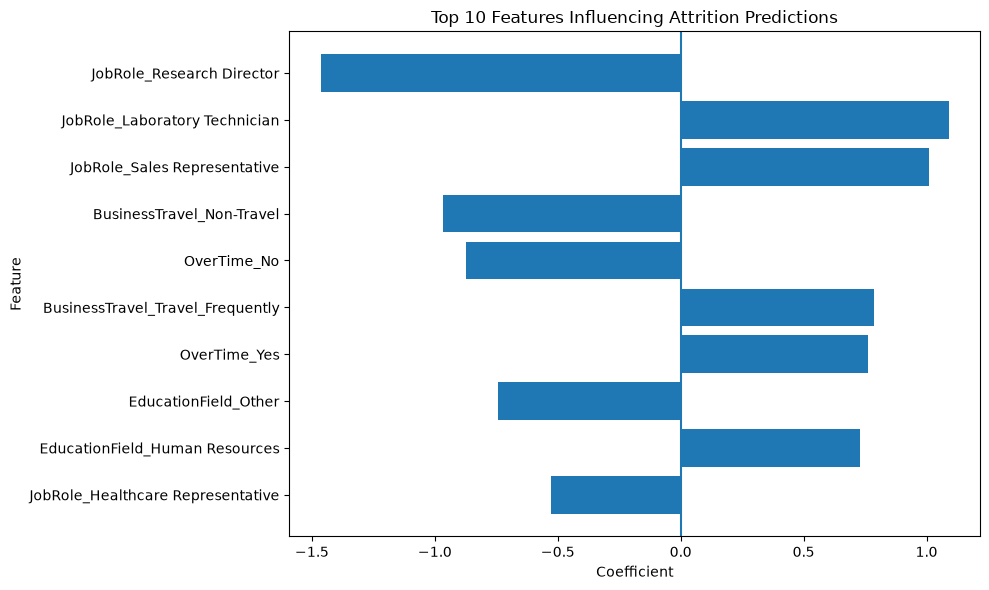

In [73]:
# Select the 10 features with the largest absolute coefficients
top_features = feature_importance.reindex(
    feature_importance['Coefficient'].abs().sort_values(ascending=False).index
).head(10)

# Create a horizontal bar chart
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.barh(top_features['Feature'], top_features['Coefficient'])
plt.axvline(0)
plt.xlabel('Coefficient')
plt.ylabel('Feature')
plt.title('Top 10 Features Influencing Attrition Predictions')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

The feature coefficient analysis shows that job role, business travel, and overtime are important factors influencing the model's attrition predictions. Sales Representatives and Laboratory Technicians, frequent business travellers, and employees who work overtime have positive coefficients, indicating higher predicted attrition. In contrast, Research Directors, employees who do not travel, and those who do not work overtime have negative coefficients, indicating lower predicted attrition.

These results show associations identified by the model and do not necessarily imply causation.

## 8.26 Machine Learning Project Conclusion

The machine learning phase focused on developing a model to predict employee attrition using Logistic Regression and Random Forest classifiers.

After evaluating both models, Logistic Regression was selected as the preferred model because it demonstrated a better ability to identify employees who actually left the organisation. The prediction threshold was adjusted from 0.5 to 0.4, increasing the model's recall to 78.72%.

The final model achieved an accuracy of 73.13%, precision of 34.91%, recall of 78.72%, an F1-score of 48.37%, and a ROC-AUC score of 0.81.

Although the model identifies approximately 79% of actual employees who left, its relatively low precision means that some employees predicted to leave may actually stay.

Overall, the project demonstrates how data analysis and machine learning can help organisations understand employee attrition patterns and identify employees who may be at risk of leaving. The model can serve as a decision-support tool for developing more effective employee retention strategies.